In [15]:
import solarpy as sp
import pandas as pd
import numpy as np
from numpy import pi, exp, sqrt, sin, cos, tan, arccos
from datetime import datetime, timedelta

import matplotlib
from matplotlib import rc
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from mpl_toolkits.axes_grid.inset_locator import (inset_axes, InsetPosition, mark_inset)

In [16]:
### load datasets

# sun radiation spectral quantities from "Preetham et al. - A Practical Analytic Model for Daylight (Appendix A.6, Table 2)"
data0 = np.loadtxt('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/S0.txt')
data1 = np.loadtxt('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/S1.txt')
data2 = np.loadtxt('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/S2.txt')

lam = data0[:,0] # wavelength spectrum

S0  = data0[:,1] # scattering 0. sun radiation mean spectral radiant power (wavelength (nm, ?))
S1  = data1[:,1] # scattering 1
S2  = data2[:,1] # scattering 2

# photopic limunosity from www.cvrl.org, "CIE Photopic V(λ) modified by Judd (1951) and Vos (1978) [also known as CIE VM(λ)]", (wavelength (nm), luminous effiency (energy)) (380-780 nm in 5 nm steps)
photopic = pd.read_csv('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/vljve.csv',skiprows=0,na_values = ['0'])
photopic_array = photopic.to_numpy()
photopic_V = photopic_array[:,1]

# scotopic limunosity from www.cvrl.org, "CIE (1951) Scotopic V'(λ)", (wavelength (nm), luminous effiency (energy)) (380-780 nm in 5 nm steps)
scotopic = pd.read_csv('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/scvle.csv',skiprows=0,na_values = ['0'])
scotopic_array = scotopic.to_numpy()
scotopic_V = scotopic_array[:,1]

### City - Latitude Dictionaries

In [17]:
### matching cities with latitudes

latitude_city = {55.7: "Moscow",
                 52  : "Berlin",
                 51.5: "London",
                 41  : "Istanbul",
                 32.8: "Tripoli",
                 30  : "Cairo",
                 25  : "Sicily",
                -33.9: "Cape Town"}

city_latitude = {"Moscow"   : 55.7,
                 "Berlin"   : 52,
                 "London"   : 51.5,
                 "Istanbul" : 41,
                 "Tripoli"  : 32.8,
                 "Cairo"    : 30,
                 "Sicily"   : 25,
                 "Cape Town":-33.9}

### Vision Throughout The Day

In [19]:
def vision_throughout_the_day(date, latitude, altitude, turbidity, theta_viewer, phi_viewer):
    
    ### the observer's viewing angle
    theta_v = theta_viewer*(pi/180) # off-zenith angle in radians (zenith=0, horizon=90)
    phi_v   = phi_viewer*(pi/180)   # azimuthal angle in radians (east=-90, south=0, west=90, north=-180)
    
    ### matrices and vectors from "Preetham et al. - A Practical Analytic Model for Daylight" (Appendix A.2)
    A1 = [[ 0.1787,-1.4630],
          [-0.3554, 0.4275],
          [-0.0227, 5.3251],
          [ 0.1206,-2.5771],
          [-0.0670, 0.3703]]
    
    A2 = [[-0.0193,-0.2592],
          [-0.0665, 0.0008],
          [-0.0004, 0.2125],
          [-0.0641,-0.8989],
          [-0.0033, 0.0452]]
    
    A3 = [[-0.0167,-0.2608],
          [-0.0950, 0.0092],
          [-0.0079, 0.2102],
          [-0.0441,-1.6537],
          [-0.0109, 0.0529]]
    
    Y_coefficient = np.dot(A1, [turbidity,1]) # [Ay, By, Cy, Dy, Ey]
    x_coefficient = np.dot(A2, [turbidity,1]) # [xy, xy, xy, xy, xy]
    y_coefficient = np.dot(A3, [turbidity,1]) # [yy, yy, yy, yy, yy]
    
    xz_matrix = [[ 0.0017,-0.0037, 0.0021, 0.0000],
                 [-0.0290, 0.0638,-0.0320, 0.0039],
                 [ 0.1169,-0.2120, 0.0605, 0.2589]]
    
    yz_matrix = [[ 0.0028,-0.0061, 0.0032, 0.0000],
                 [-0.0421, 0.0897,-0.0415, 0.0052],
                 [ 0.1535,-0.2676, 0.0667, 0.2669]]
    
    T_vector = [turbidity**2,turbidity,1]
    
    vision = []
    vision_sc = []
    vision_pc = []
    
    for i in range(144):
    
        m = 10*i
        
        theta_s = sp.theta_z(date+timedelta(minutes=m),latitude)
        phi_s = sp.solar_azimuth(date+timedelta(minutes=m),latitude)
        
        gamma = arccos(cos(theta_v)*cos(theta_s) + sin(theta_v)*cos(phi_v)*sin(theta_s)*cos(phi_s) + sin(theta_v)*sin(phi_v)*sin(theta_s)*sin(phi_s))
        
        Chi = (4/9 - turbidity/120)*(pi - 2*theta_s)
        Yz = (4.0453*turbidity - 4.9710)*tan(Chi) - 0.2155*turbidity + 2.4192
        
        theta_s_vector = [theta_s**3,theta_s**2,theta_s,1]
        
        xz = np.dot(T_vector,xz_matrix)
        xz = np.dot(xz, theta_s_vector)
        
        yz = np.dot(T_vector,yz_matrix)
        yz = np.dot(yz, theta_s_vector)
        
        
        FY_theta_gamma = (1+Y_coefficient[0]*exp(Y_coefficient[1]/cos(theta_v))) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*gamma) + Y_coefficient[4]*(cos(gamma))**2)
        FY_0_theta_s = (1+Y_coefficient[0]*exp(Y_coefficient[1])) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*theta_s) + Y_coefficient[4]*(cos(theta_s))**2)
        
        Fx_theta_gamma = (1+x_coefficient[0]*exp(x_coefficient[1]/cos(theta_v))) * (1+x_coefficient[2]*exp(x_coefficient[3]*gamma) + x_coefficient[4]*(cos(gamma))**2)
        Fx_0_theta_s = (1+x_coefficient[0]*exp(x_coefficient[1])) * (1+x_coefficient[2]*exp(x_coefficient[3]*theta_s) + x_coefficient[4]*(cos(theta_s))**2)
        
        Fy_theta_gamma = (1+y_coefficient[0]*exp(y_coefficient[1]/cos(theta_v))) * (1+y_coefficient[2]*exp(y_coefficient[3]*gamma) + y_coefficient[4]*(cos(gamma))**2)
        Fy_0_theta_s = (1+y_coefficient[0]*exp(y_coefficient[1])) * (1+y_coefficient[2]*exp(y_coefficient[3]*theta_s)+ y_coefficient[4]*(cos(theta_s))**2)
        
        
        Y = Yz*(FY_theta_gamma/FY_0_theta_s)
        x = xz*(Fx_theta_gamma/Fx_0_theta_s)
        y = yz*(Fy_theta_gamma/Fy_0_theta_s)
        
        M1 = (-1.3515-1.7703*x+5.9114*y)/(0.0241+0.2562*x-0.7341*y)
        M2 = (0.0300-31.4424*x+30.0717*y)/(0.0241+0.2562*x-0.7341*y)
        
        SD = np.array(S0) + M1*np.array(S1) + M2*np.array(S2)
        
        #for i in range(len(SD)):
        #    if SD[i] < 0:
        #        SD[i] = S0[i]
        #    else: pass
        
        scotopic_vision = SD*scotopic_V
        photopic_vision = SD*photopic_V   
        
        vision_sc.append(sum(scotopic_vision))
        vision_pc.append(sum(photopic_vision))
        vision.append((sum(scotopic_vision)+sum(photopic_vision)))
        
    #time_scale = [i/60 for i in range(0,1440,10)]
    time_scale = [date+timedelta(minutes=i) for i in range(0, 6*10*24, 10)]
    
    return time_scale, vision_sc, vision_pc, vision

In [20]:
### run - vision_throughout_the_day

day = [datetime(2020,3,21),
       datetime(2020,6,21),
       datetime(2020,10,24),
       datetime(2020,12,24)]

lat = [25, 41, 52]
alt = 25
tur = 2

Theta_v = 80 # (zenith=0, horizon=90)
Phi_v   = 270 # (east=-90, south=0, west=90, north=180)

t1, Vsc1, Vpc1, V1  = vision_throughout_the_day(day[0],lat[0],alt,tur,Theta_v,Phi_v)
t2, Vsc2, Vpc2, V2  = vision_throughout_the_day(day[0],lat[1],alt,tur,Theta_v,Phi_v)
t3, Vsc3, Vpc3, V3  = vision_throughout_the_day(day[0],lat[2],alt,tur,Theta_v,Phi_v)

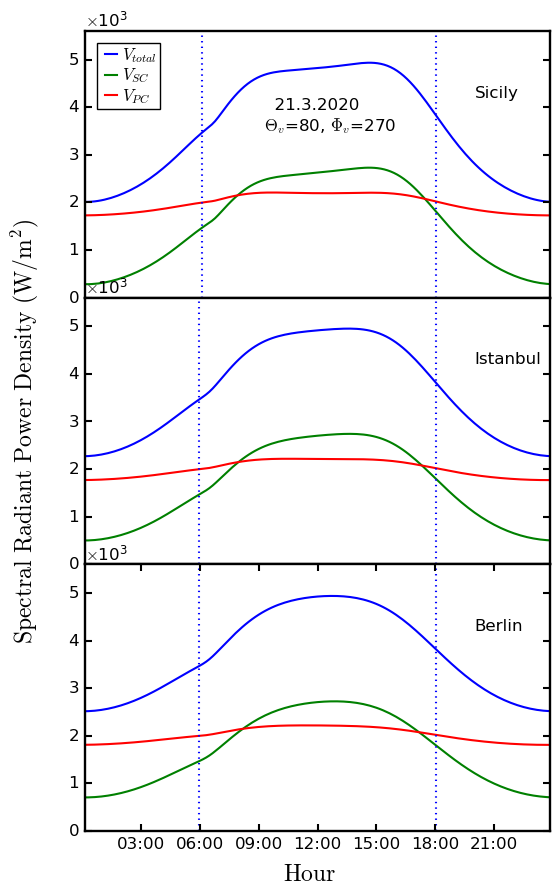

In [23]:
### plot - vision_throughout_the_day

plt.style.use('classic')
linewidth = 1.7
sizeoffonts = 12
rc('lines', linewidth=1.5)
rc('axes', linewidth=linewidth)
rc('legend', labelspacing=0,
             handlelength=0,
             handletextpad=-0.1,
             columnspacing=-0.1,
             borderpad=0.1,
             borderaxespad=0.2,
             fontsize=sizeoffonts-2)

color = ['blue', 'green', 'red']

fig = plt.figure(figsize=(6,10), dpi=100)
fig.set_facecolor('none')
fig.text(0.0, 0.5, "$\mathrm{Spectral}$ $\mathrm{Radiant}$ $\mathrm{Power}$ $\mathrm{Density}$ $\mathrm{(W/m^2)}$", va='center', rotation='vertical', fontsize=sizeoffonts+5)
fig.text(0.5, 0.05, "$\mathrm{Hour}$", ha='center', fontsize=sizeoffonts+5)


### figure (a)
ax1 = plt.subplot(311)
ax1.plot(t1, V1,   label="$V_{total}$", color=color[0])
ax1.plot(t1, Vsc1, label="$V_{SC}$",    color=color[1])
ax1.plot(t1, Vpc1, label="$V_{PC}$",    color=color[2])
myFmt = mdates.DateFormatter('%H:%M')
ax1.xaxis.set_major_formatter(myFmt)

#ax1.set_xlim(t1[1], t1[-1])
ax1.set_ylim(0, 5.6e3)
#ax1.xaxis.set_ticks([0, 0.3, 0.6, 0.9])
ax1.yaxis.set_ticks([0, 1e3, 2e3, 3e3, 4e3, 5e3])
ax1.set_xticks([])
#ax1.set_yticks([])
plt.ticklabel_format(axis='y', style="sci", useMathText=True, useOffset=True, useLocale=False, scilimits=(0,0))
ax1.tick_params(axis="both", direction="in", width=1.5, length=5, labelsize=sizeoffonts)

ax1.legend(loc='upper left',
         #bbox_to_anchor=(0.31, 0.7),
          prop={'size':sizeoffonts},
         #title="$\mathrm{T/T_c}$",
          labelspacing=.1,
          handlelength=1.3,
          handletextpad=0.,
          borderpad=0.2,
          borderaxespad=0.7)

ax1.text(t1[55],3500, "  "+str(day[0].day)+"."+str(day[0].month)+"."+str(day[0].year)+
                   "\n$\Theta_v$="+str(np.round(Theta_v,3))+", $\Phi_v$="+str(np.round(Phi_v,3)), fontsize=sizeoffonts)

ax1.text(t1[120],4200, latitude_city[lat[0]], fontsize=sizeoffonts)

plt.axvline(sp.sunrise_time(day[0],lat[0]), ls=':')
plt.axvline(sp.sunset_time(day[0],lat[0]),  ls=':')
#plt.axhline(0, ls='--')


### figure (b)
ax2 = plt.subplot(312)
ax2.plot(t2, V2,   label="$V_{total}$", color=color[0])
ax2.plot(t2, Vsc2, label="$V_{SC}$",    color=color[1])
ax2.plot(t2, Vpc2, label="$V_{PC}$",    color=color[2])
myFmt = mdates.DateFormatter('%H:%M')
ax2.xaxis.set_major_formatter(myFmt)

ax2.set_xlim(t2[1], t2[-1])
ax2.set_ylim(0, 5.6e3)
#ax2.xaxis.set_ticks([0, 0.3, 0.6, 0.9])
ax2.yaxis.set_ticks([0, 1e3, 2e3, 3e3, 4e3, 5e3])
ax2.set_xticks([])
#ax2.set_yticks([])
plt.ticklabel_format(axis='y', style="sci", useMathText=True, useOffset=True, useLocale=False, scilimits=(0,0))
ax2.tick_params(axis="both", direction="in", width=1.5, length=5, labelsize=sizeoffonts)

ax2.text(t2[120],4200, latitude_city[lat[1]], fontsize=sizeoffonts)

plt.axvline(sp.sunrise_time(day[0],lat[1]), ls=':')
plt.axvline(sp.sunset_time(day[0],lat[1]),  ls=':')
#plt.axhline(0, ls='--')


### figure (c)
ax3 = plt.subplot(313)
ax3.plot(t3, V3,   label="$V_{total}$", color=color[0])
ax3.plot(t3, Vsc3, label="$V_{SC}$",    color=color[1])
ax3.plot(t3, Vpc3, label="$V_{PC}$",    color=color[2])
myFmt = mdates.DateFormatter('%H:%M')
ax3.xaxis.set_major_formatter(myFmt)

ax3.set_xlim(t3[1], t3[-1])
ax3.set_ylim(0, 5.6e3)
#ax3.xaxis.set_ticks([0, 0.3, 0.6, 0.9])
ax3.yaxis.set_ticks([0, 1e3, 2e3, 3e3, 4e3, 5e3])
#ax3.set_xticks([])
#ax3.set_yticks([])
plt.ticklabel_format(axis='y', style="sci", useMathText=True, useOffset=True, useLocale=False, scilimits=(0,0))
ax3.tick_params(axis="both", direction="in", width=1.5, length=5, labelsize=sizeoffonts)

ax3.text(t3[120],4200, latitude_city[lat[2]], fontsize=sizeoffonts)

plt.axvline(sp.sunrise_time(day[0],lat[2]), ls=':')
plt.axvline(sp.sunset_time(day[0],lat[2]),  ls=':')
#plt.axhline(0, ls='--')

plt.subplots_adjust(wspace=0, hspace=0)
plt.show()

#fig.savefig(r"/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Results/RadiantPower_Hour_Phi"+str(Phi_v)+".png", format='png', bbox_inches='tight')

### Vision at A Moment

In [12]:
def vision_at_a_moment(moment, latitude, altitude, turbidity, theta_viewer, phi_viewer):
    
    ### the observer's viewing angle
    theta_v = theta_viewer*(pi/180) # off-zenith angle in radians (zenith=0, horizon=90)
    phi_v = phi_viewer*(pi/180) # azimuthal angle in radians (east=-90, south=0, west=90, north=-180)
    
    ### matrices and vectors from "Preetham et al. - A Practical Analytic Model for Daylight" (Appendix A.2)
    A1 = [[ 0.1787,-1.4630],
          [-0.3554, 0.4275],
          [-0.0227, 5.3251],
          [ 0.1206,-2.5771],
          [-0.0670, 0.3703]]
    
    A2 = [[-0.0193,-0.2592],
          [-0.0665, 0.0008],
          [-0.0004, 0.2125],
          [-0.0641,-0.8989],
          [-0.0033, 0.0452]]
    
    A3 = [[-0.0167,-0.2608],
          [-0.0950, 0.0092],
          [-0.0079, 0.2102],
          [-0.0441,-1.6537],
          [-0.0109, 0.0529]]
    
    Y_coefficient = np.dot(A1, [turbidity,1]) # [Ay, By, Cy, Dy, Ey]
    x_coefficient = np.dot(A2, [turbidity,1]) # [xy, xy, xy, xy, xy]
    y_coefficient = np.dot(A3, [turbidity,1]) # [yy, yy, yy, yy, yy]
    
    xz_matrix = [[ 0.0017,-0.0037, 0.0021, 0.0000],
                 [-0.0290, 0.0638,-0.0320, 0.0039],
                 [ 0.1169,-0.2120, 0.0605, 0.2589]]
    
    yz_matrix = [[ 0.0028,-0.0061, 0.0032, 0.0000],
                 [-0.0421, 0.0897,-0.0415, 0.0052],
                 [ 0.1535,-0.2676, 0.0667, 0.2669]]
    
    T_vector = [turbidity**2,turbidity,1]
    
    theta_s = sp.theta_z(moment,latitude)
    phi_s = sp.solar_azimuth(moment,latitude)
    
    gamma = arccos(cos(theta_v)*cos(theta_s) + sin(theta_v)*cos(phi_v)*sin(theta_s)*cos(phi_s) + sin(theta_v)*sin(phi_v)*sin(theta_s)*sin(phi_s))
    
    Chi = (4/9 - turbidity/120)*(pi - 2*theta_s)
    Yz = (4.0453*turbidity - 4.9710)*tan(Chi) - 0.2155*turbidity + 2.4192
    
    theta_s_vector = [theta_s**3,theta_s**2,theta_s,1]
    
    xz = np.dot(T_vector,xz_matrix)
    xz = np.dot(xz, theta_s_vector)
    
    yz = np.dot(T_vector,yz_matrix)
    yz = np.dot(yz, theta_s_vector)
    
    
    FY_theta_gamma = (1+Y_coefficient[0]*exp(Y_coefficient[1]/cos(theta_v))) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*gamma) + Y_coefficient[4]*(cos(gamma))**2)
    FY_0_theta_s = (1+Y_coefficient[0]*exp(Y_coefficient[1])) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*theta_s) + Y_coefficient[4]*(cos(theta_s))**2)
        
    Fx_theta_gamma = (1+x_coefficient[0]*exp(x_coefficient[1]/cos(theta_v))) * (1+x_coefficient[2]*exp(x_coefficient[3]*gamma) + x_coefficient[4]*(cos(gamma))**2)
    Fx_0_theta_s = (1+x_coefficient[0]*exp(x_coefficient[1])) * (1+x_coefficient[2]*exp(x_coefficient[3]*theta_s) + x_coefficient[4]*(cos(theta_s))**2)
        
    Fy_theta_gamma = (1+y_coefficient[0]*exp(y_coefficient[1]/cos(theta_v))) * (1+y_coefficient[2]*exp(y_coefficient[3]*gamma) + y_coefficient[4]*(cos(gamma))**2)
    Fy_0_theta_s = (1+y_coefficient[0]*exp(y_coefficient[1])) * (1+y_coefficient[2]*exp(y_coefficient[3]*theta_s)+ y_coefficient[4]*(cos(theta_s))**2)
    
    Y = Yz*(FY_theta_gamma/FY_0_theta_s)
    x = xz*(Fx_theta_gamma/Fx_0_theta_s)
    y = yz*(Fy_theta_gamma/Fy_0_theta_s)
    
    M1 = (-1.3515-1.7703*x+5.9114*y)/(0.0241+0.2562*x-0.7341*y)
    M2 = (0.0300-31.4424*x+30.0717*y)/(0.0241+0.2562*x-0.7341*y)
    
    SD = np.array(S0) + M1*np.array(S1) + M2*np.array(S2)
    
    #for i in range(len(SD)):
    #    if SD[i] < 0:
    #        SD[i] = S0[i]
    #    else: pass
    
    scotopic_vision = SD*scotopic_V
    photopic_vision = SD*photopic_V
    
    return SD, scotopic_vision, photopic_vision

In [13]:
### run - vision_at_a_moment

day = [datetime(2020,3,21),
       datetime(2020,6,21),
       datetime(2020,10,24),
       datetime(2020,12,24)]

moment = [timedelta(minutes=60* 7),
          timedelta(minutes=60* 12),
          timedelta(minutes=60* 15.5),
          timedelta(minutes=60* 22)]

lat = [25, 41, 52]
alt = 25
tur = 2

Theta_v = 80
Phi_v   = 0


S_d1_1, V_sc1_1, V_pc1_1 = vision_at_a_moment(day[0]+moment[0],lat[1],alt,tur,Theta_v,Phi_v)
S_d1_2, V_sc1_2, V_pc1_2 = vision_at_a_moment(day[0]+moment[1],lat[1],alt,tur,Theta_v,Phi_v)
S_d1_3, V_sc1_3, V_pc1_3 = vision_at_a_moment(day[0]+moment[2],lat[1],alt,tur,Theta_v,Phi_v)
S_d1_4, V_sc1_4, V_pc1_4 = vision_at_a_moment(day[0]+moment[3],lat[1],alt,tur,Theta_v,Phi_v)

S_d2_1, V_sc2_1, V_pc2_1 = vision_at_a_moment(day[1]+moment[0],lat[1],alt,tur,Theta_v,Phi_v)
S_d2_2, V_sc2_2, V_pc2_2 = vision_at_a_moment(day[1]+moment[1],lat[1],alt,tur,Theta_v,Phi_v)
S_d2_3, V_sc2_3, V_pc2_3 = vision_at_a_moment(day[1]+moment[2],lat[1],alt,tur,Theta_v,Phi_v)
S_d2_4, V_sc2_4, V_pc2_4 = vision_at_a_moment(day[1]+moment[3],lat[1],alt,tur,Theta_v,Phi_v)

S_d3_1, V_sc3_1, V_pc3_1 = vision_at_a_moment(day[2]+moment[0],lat[1],alt,tur,Theta_v,Phi_v)
S_d3_2, V_sc3_2, V_pc3_2 = vision_at_a_moment(day[2]+moment[1],lat[1],alt,tur,Theta_v,Phi_v)
S_d3_3, V_sc3_3, V_pc3_3 = vision_at_a_moment(day[2]+moment[2],lat[1],alt,tur,Theta_v,Phi_v)
S_d3_4, V_sc3_4, V_pc3_4 = vision_at_a_moment(day[2]+moment[3],lat[1],alt,tur,Theta_v,Phi_v)

S_d4_1, V_sc4_1, V_pc4_1 = vision_at_a_moment(day[3]+moment[0],lat[1],alt,tur,Theta_v,Phi_v)
S_d4_2, V_sc4_2, V_pc4_2 = vision_at_a_moment(day[3]+moment[1],lat[1],alt,tur,Theta_v,Phi_v)
S_d4_3, V_sc4_3, V_pc4_3 = vision_at_a_moment(day[3]+moment[2],lat[1],alt,tur,Theta_v,Phi_v)
S_d4_4, V_sc4_4, V_pc4_4 = vision_at_a_moment(day[3]+moment[3],lat[1],alt,tur,Theta_v,Phi_v)

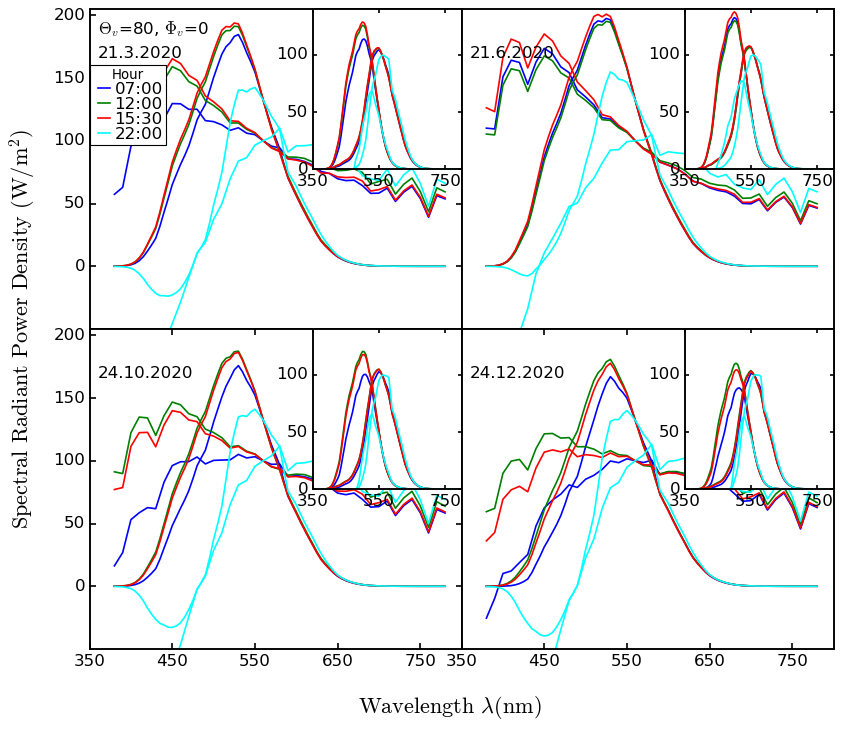

In [14]:
### plot - vision_at_a_moment

plt.style.use('classic')
linewidth = 1.7
sizeoffonts = 15
rc('lines', linewidth=1.5)
rc('axes', linewidth=linewidth)
rc('legend', labelspacing=0,
             handlelength=0,
             handletextpad=-0.1,
             columnspacing=-0.1,
             borderpad=0.1,
             borderaxespad=0.2,
             fontsize=sizeoffonts-2)

fig = plt.figure(figsize=(12,10), dpi=80)
fig.set_facecolor('none')
fig.text(0.04, 0.5, "$\mathrm{Spectral}$ $\mathrm{Radiant}$ $\mathrm{Power}$ $\mathrm{Density}$ $\mathrm{(W/m^2)}$", va='center', rotation='vertical', fontsize=sizeoffonts+5)
fig.text(0.5, 0.02, "$\mathrm{Wavelength}$ $\mathrm{\lambda(nm)}$", ha='center', fontsize=sizeoffonts+5)

color = ['blue', 'green', 'red', 'aqua', 'black', 'pink']

###################################################################### figure (a)
ax1 = plt.subplot(221)
ax1.plot(lam, S_d1_1,  color=color[0])
#ax1.plot(lam, V_sc1_1, color=color[0])
#ax1.plot(lam, V_pc1_1, color=color[0])
V_tot1_1 = V_sc1_1+V_pc1_1
seconds = moment[0].seconds//60 # H:M formatter for plot label
minutes = seconds//60           #
seconds %= 60                   #
ax1.plot(lam, V_tot1_1, label="%02i:%02i"%(minutes,seconds), color=color[0])
#for i in range(len(V_tot1_1)):
#    if V_tot1_1[i] == max(V_tot1_1):
#        plt.axvline(lam[i], ls=':')
#        break
#    else: pass
        
ax1.plot(lam, S_d1_2, color=color[1])
#ax1.plot(lam, V_sc1_2, color=color[1])
#ax1.plot(lam, V_pc1_2, color=color[1])
V_tot1_2 = V_sc1_2+V_pc1_2
seconds = moment[1].seconds//60 # H:M formatter for plot label
minutes = seconds//60           #
seconds %= 60                   #
ax1.plot(lam, V_tot1_2,  label="%02i:%02i"%(minutes,seconds), color=color[1])

ax1.plot(lam, S_d1_3, color=color[2])
#ax1.plot(lam, V_sc1_3, color=color[2])
#ax1.plot(lam, V_pc1_3, color=color[2])
V_tot1_3 = V_sc1_3+V_pc1_3
seconds = moment[2].seconds//60 # H:M formatter for plot label
minutes = seconds//60           #
seconds %= 60   
ax1.plot(lam, V_tot1_3, label="%02i:%02i"%(minutes,seconds), color=color[2])

ax1.plot(lam, S_d1_4, color=color[3])
#ax1.plot(lam, V_sc1_4, color=color[3])
#ax1.plot(lam, V_pc1_4, color=color[3])
V_tot1_4 = V_sc1_4+V_pc1_4
seconds = moment[3].seconds//60 # H:M formatter for plot label
minutes = seconds//60           #
seconds %= 60   
ax1.plot(lam, V_tot1_4,  label="%02i:%02i"%(minutes,seconds), color=color[3])
    
ax1.set_xlim(350, 800)
ax1.set_ylim(-50, 205)
ax1.xaxis.set_ticks([350, 450, 550, 650, 750])
ax1.yaxis.set_ticks([0, 50, 100, 150, 200])
ax1.set_xticks([])
#ax1.set_yticks([])
ax1.tick_params(axis="both", direction="in", width=1.5, length=5, labelsize=sizeoffonts)

ax1.legend(loc='center left',
          ncol=1,
          bbox_to_anchor=(0,0.7),
          prop={'size':sizeoffonts},
          title="Hour",
          columnspacing=.2,
          labelspacing=0,
          handlelength=1.3,
          handletextpad=0.,
          borderpad=0.2,
          borderaxespad=0)

ax1.text(360,185, "$\Theta_v$="+str(np.round(Theta_v,3))+", $\Phi_v$="+str(np.round(Phi_v,3)), fontsize=sizeoffonts)
ax1.text(360,166, str(day[0].day)+"."+str(day[0].month)+"."+str(day[0].year), fontsize=sizeoffonts)

################################################ inset (a)
ax1_inset = ax1.inset_axes([0.6,0.5, 0.4,0.5])
ax1_inset.plot(lam, V_sc1_1, color=color[0])
ax1_inset.plot(lam, V_pc1_1, color=color[0])
ax1_inset.plot(lam, V_sc1_2, color=color[1])
ax1_inset.plot(lam, V_pc1_2, color=color[1])
ax1_inset.plot(lam, V_sc1_3, color=color[2])
ax1_inset.plot(lam, V_pc1_3, color=color[2])
ax1_inset.plot(lam, V_sc1_4, color=color[3])
ax1_inset.plot(lam, V_pc1_4, color=color[3])
ax1_inset.axis([350,800, 0,140])
ax1_inset.xaxis.set_ticks([350, 550, 750])
ax1_inset.yaxis.set_ticks([0, 50, 100])
ax1_inset.tick_params(axis="both", direction="in", width=1.5, length=4, labelsize=sizeoffonts)


###################################################################### figure (b)
ax2 = plt.subplot(222)
ax2.plot(lam, S_d2_1, color=color[0])
#ax2.plot(lam, V_sc2_1, color=color[0])
#ax2.plot(lam, V_pc2_1, color=color[0])
V_tot2_1 = V_sc2_1+V_pc2_1
ax2.plot(lam, V_tot2_1,  label=str(moment[0]), color=color[0])
        
ax2.plot(lam, S_d2_2, color=color[1])
#ax2.plot(lam, V_sc2_2, color=color[1])
#ax2.plot(lam, V_pc2_2, color=color[1])
V_tot2_2 = V_sc2_2+V_pc2_2
ax2.plot(lam, V_tot2_2,  label=str(moment[1]), color=color[1])

ax2.plot(lam, S_d2_3, color=color[2])
#ax2.plot(lam, V_sc2_3, color=color[2])
#ax2.plot(lam, V_pc2_3, color=color[2])
V_tot2_3 = V_sc2_3+V_pc2_3
ax2.plot(lam, V_tot2_3,  label=str(moment[2]), color=color[2])

ax2.plot(lam, S_d2_4, color=color[3])
#ax2.plot(lam, V_sc2_4, color=color[3])
#ax2.plot(lam, V_pc2_4, color=color[3])
V_tot2_4 = V_sc2_4+V_pc2_4
ax2.plot(lam, V_tot2_4,  label=str(moment[3]), color=color[3])
    
ax2.set_xlim(350, 800)
ax2.set_ylim(-50, 205)
ax2.xaxis.set_ticks([350, 450, 550, 650, 750])
ax2.yaxis.set_ticks([0, 50, 100, 150, 200])
ax2.set_xticks([])
ax2.set_yticks([])
ax2.tick_params(axis="both", direction="in", width=1.5, length=5, labelsize=sizeoffonts)

ax2.text(360,166, str(day[1].day)+"."+str(day[1].month)+"."+str(day[1].year), fontsize=sizeoffonts)

################################################ inset (a)
ax2_inset = ax2.inset_axes([0.6,0.5, 0.4,0.5])
ax2_inset.plot(lam, V_sc2_1, color=color[0])
ax2_inset.plot(lam, V_pc2_1, color=color[0])
ax2_inset.plot(lam, V_sc2_2, color=color[1])
ax2_inset.plot(lam, V_pc2_2, color=color[1])
ax2_inset.plot(lam, V_sc2_3, color=color[2])
ax2_inset.plot(lam, V_pc2_3, color=color[2])
ax2_inset.plot(lam, V_sc2_4, color=color[3])
ax2_inset.plot(lam, V_pc2_4, color=color[3])
ax2_inset.axis([350,800, 0,140])
ax2_inset.xaxis.set_ticks([350, 550, 750])
ax2_inset.yaxis.set_ticks([0, 50, 100])
ax2_inset.tick_params(axis="both", direction="in", width=1.5, length=4, labelsize=sizeoffonts)

###################################################################### figure (c)
ax3 = plt.subplot(223)
ax3.plot(lam, S_d3_1, color=color[0])
#ax3.plot(lam, V_sc3_1, color=color[0])
#ax3.plot(lam, V_pc3_1, color=color[0])
V_tot3_1 = V_sc3_1+V_pc3_1
ax3.plot(lam, V_tot3_1,   label="$V_{total}$", color=color[0])
        
ax3.plot(lam, S_d3_2, color=color[1])
#ax3.plot(lam, V_sc3_2, color=color[1])
#ax3.plot(lam, V_pc3_2, color=color[1])
V_tot3_2 = V_sc3_2+V_pc3_2
ax3.plot(lam, V_tot3_2,   label="$V_{total}$", color=color[1])

ax3.plot(lam, S_d3_3, color=color[2])
#ax3.plot(lam, V_sc3_3, color=color[2])
#ax3.plot(lam, V_pc3_3, color=color[2])
V_tot3_3 = V_sc3_3+V_pc3_3
ax3.plot(lam, V_tot3_3,   label="$V_{total}$", color=color[2])

ax3.plot(lam, S_d3_4, color=color[3])
#ax3.plot(lam, V_sc3_4, color=color[3])
#ax3.plot(lam, V_pc3_4, color=color[3])
V_tot3_4 = V_sc3_4+V_pc3_4
ax3.plot(lam, V_tot3_4,   label="$V_{total}$", color=color[3])
    
ax3.set_xlim(350, 800)
ax3.set_ylim(-50, 205)
ax3.xaxis.set_ticks([350, 450, 550, 650, 750])
ax3.yaxis.set_ticks([0, 50, 100, 150, 200])
#ax3.set_xticks([])
#ax3.set_yticks([])
ax3.tick_params(axis="both", direction="in", width=1.5, length=5, labelsize=sizeoffonts)

ax3.text(360,166, str(day[2].day)+"."+str(day[2].month)+"."+str(day[2].year), fontsize=sizeoffonts)

################################################ inset (a)
ax3_inset = ax3.inset_axes([0.6,0.5, 0.4,0.5])
ax3_inset.plot(lam, V_sc3_1, color=color[0])
ax3_inset.plot(lam, V_pc3_1, color=color[0])
ax3_inset.plot(lam, V_sc3_2, color=color[1])
ax3_inset.plot(lam, V_pc3_2, color=color[1])
ax3_inset.plot(lam, V_sc3_3, color=color[2])
ax3_inset.plot(lam, V_pc3_3, color=color[2])
ax3_inset.plot(lam, V_sc3_4, color=color[3])
ax3_inset.plot(lam, V_pc3_4, color=color[3])
ax3_inset.axis([350,800, 0,140])
ax3_inset.xaxis.set_ticks([350, 550, 750])
ax3_inset.yaxis.set_ticks([0, 50, 100])
ax3_inset.tick_params(axis="both", direction="in", width=1.5, length=4, labelsize=sizeoffonts)


###################################################################### figure (d)
ax4 = plt.subplot(224)
ax4.plot(lam, S_d4_1, color=color[0])
#ax4.plot(lam, V_sc4_1, color=color[0])
#ax4.plot(lam, V_pc4_1, color=color[0])
V_tot4_1 = V_sc4_1+V_pc4_1
ax4.plot(lam, V_tot4_1,   label="$V_{total}$", color=color[0])
        
ax4.plot(lam, S_d4_2, color=color[1])
#ax4.plot(lam, V_sc4_2, color=color[1])
#ax4.plot(lam, V_pc4_2, color=color[1])
V_tot4_2 = V_sc4_2+V_pc4_2
ax4.plot(lam, V_tot4_2,   label="$V_{total}$", color=color[1])

ax4.plot(lam, S_d4_3, color=color[2])
#ax4.plot(lam, V_sc4_3, color=color[2])
#ax4.plot(lam, V_pc4_3, color=color[2])
V_tot4_3 = V_sc4_3+V_pc4_3
ax4.plot(lam, V_tot4_3,   label="$V_{total}$", color=color[2])

ax4.plot(lam, S_d4_4, color=color[3])
#ax4.plot(lam, V_sc4_4, color=color[3])
#ax4.plot(lam, V_pc4_4, color=color[3])
V_tot4_4 = V_sc4_4+V_pc4_4
ax4.plot(lam, V_tot4_4,   label="$V_{total}$", color=color[3])
    
ax4.set_xlim(350, 800)
ax4.set_ylim(-50, 205)
ax4.xaxis.set_ticks([350, 450, 550, 650, 750])
ax4.yaxis.set_ticks([0, 50, 100, 150, 200])
#ax4.set_xticks([])
ax4.set_yticks([])
ax4.tick_params(axis="both", direction="in", width=1.5, length=5, labelsize=sizeoffonts)

ax4.text(360,166, str(day[3].day)+"."+str(day[3].month)+"."+str(day[3].year), fontsize=sizeoffonts)

################################################ inset (a)
ax4_inset = ax4.inset_axes([0.6,0.5, 0.4,0.5])
ax4_inset.plot(lam, V_sc4_1, color=color[0])
ax4_inset.plot(lam, V_pc4_1, color=color[0])
ax4_inset.plot(lam, V_sc4_2, color=color[1])
ax4_inset.plot(lam, V_pc4_2, color=color[1])
ax4_inset.plot(lam, V_sc4_3, color=color[2])
ax4_inset.plot(lam, V_pc4_3, color=color[2])
ax4_inset.plot(lam, V_sc4_4, color=color[3])
ax4_inset.plot(lam, V_pc4_4, color=color[3])
ax4_inset.axis([350,800, 0,140])
ax4_inset.xaxis.set_ticks([350, 550, 750])
ax4_inset.yaxis.set_ticks([0, 50, 100])
ax4_inset.tick_params(axis="both", direction="in", width=1.5, length=4, labelsize=sizeoffonts)



plt.subplots_adjust(wspace=0, hspace=0)
plt.show()

#fig.savefig(r"/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Results/RadiantPower_Wavelength/RadiantPower_Wavelength_Phi"+str(Phi_v)+".png", format='png', bbox_inches='tight')